# AdaBoost

Boosting with decision **stumps** (one-split trees), each barely better than guessing. Rounds are sequential:

1. Train a stump on the weighted data; compute its weighted error `err`.
2. Give it a vote strength `alpha = ½ ln((1 − err) / err)` — more accurate stumps count more.
3. Re-weight samples: `w *= exp(−alpha · y · pred)`. Misclassified samples grow, so the next stump focuses on them.

Prediction is `sign(Σ alpha · stump(x))`.

Compare `22_gradient_boosting` (fits residuals) and `19_random_forest` (independent trees, parallel). Binary classification only; labels can be any two values.

## Usage

```python
# (the class is defined in the Implementation section below)

model = AdaBoostClassifier(n_estimators=50).fit(X_train, y_train)
preds = model.predict(X_test)
scores = model.decision_function(X_test)   # signed vote total
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class _Stump:
    """One-split tree: predicts `polarity` when x[feature] > threshold, else -polarity."""

    def fit(self, X, y, w):
        best_err = np.inf
        for f in range(X.shape[1]):
            order = np.argsort(X[:, f])
            xs, ys, ws = X[order, f], y[order], w[order]
            # weighted error of "left = -1, right = +1" for every split point, via cumulative sums
            pos_left = np.cumsum(ws * (ys == 1))[:-1]
            neg_left = np.cumsum(ws * (ys == -1))[:-1]
            err = pos_left + (np.sum(ws * (ys == -1)) - neg_left)
            err = np.where(xs[1:] != xs[:-1], err, 0.5)  # can't split between equal values
            for polarity, e in ((1, err), (-1, 1 - err)):  # flipping the stump flips its error
                i = e.argmin()
                if e[i] < best_err:
                    best_err = e[i]
                    self.feature, self.polarity = f, polarity
                    self.threshold = (xs[i] + xs[i + 1]) / 2
        return self

    def predict(self, X):
        return self.polarity * np.where(X[:, self.feature] > self.threshold, 1, -1)


class AdaBoostClassifier:
    """Binary AdaBoost with decision stumps. Each round up-weights the samples the previous
    stumps got wrong; the final prediction is a weighted vote of all stumps."""

    def __init__(self, n_estimators=50):
        self.n_estimators = n_estimators
        self.classes_ = None
        self.stumps, self.alphas = [], []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_, y_enc = np.unique(y, return_inverse=True)
        if len(self.classes_) != 2:
            raise ValueError("AdaBoostClassifier is binary: needs exactly 2 classes")
        y_pm = 2 * y_enc - 1  # {0, 1} -> {-1, +1}

        w = np.full(len(y_pm), 1 / len(y_pm))
        self.stumps, self.alphas = [], []
        for _ in range(self.n_estimators):
            stump = _Stump().fit(X, y_pm, w)
            pred = stump.predict(X)
            err = np.clip(w[pred != y_pm].sum(), 1e-10, 1 - 1e-10)
            alpha = 0.5 * np.log((1 - err) / err)  # accurate stumps get a bigger say
            w *= np.exp(-alpha * y_pm * pred)  # wrong samples grow, right ones shrink
            w /= w.sum()
            self.stumps.append(stump)
            self.alphas.append(alpha)
            if err <= 1e-10:  # perfect stump: nothing left to fix
                break
        return self

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)
        return sum(a * s.predict(X) for a, s in zip(self.alphas, self.stumps))

    def predict(self, X):
        return self.classes_[(self.decision_function(X) > 0).astype(int)]

## See it work

### 1. A weighted vote of stumps

Each weak learner is a **decision stump**: one split on one feature. One stump is a straight, axis-aligned cut. AdaBoost adds stumps one at a time; the final classifier is the sign of the weighted vote, which can carve out a curved region from many straight cuts.

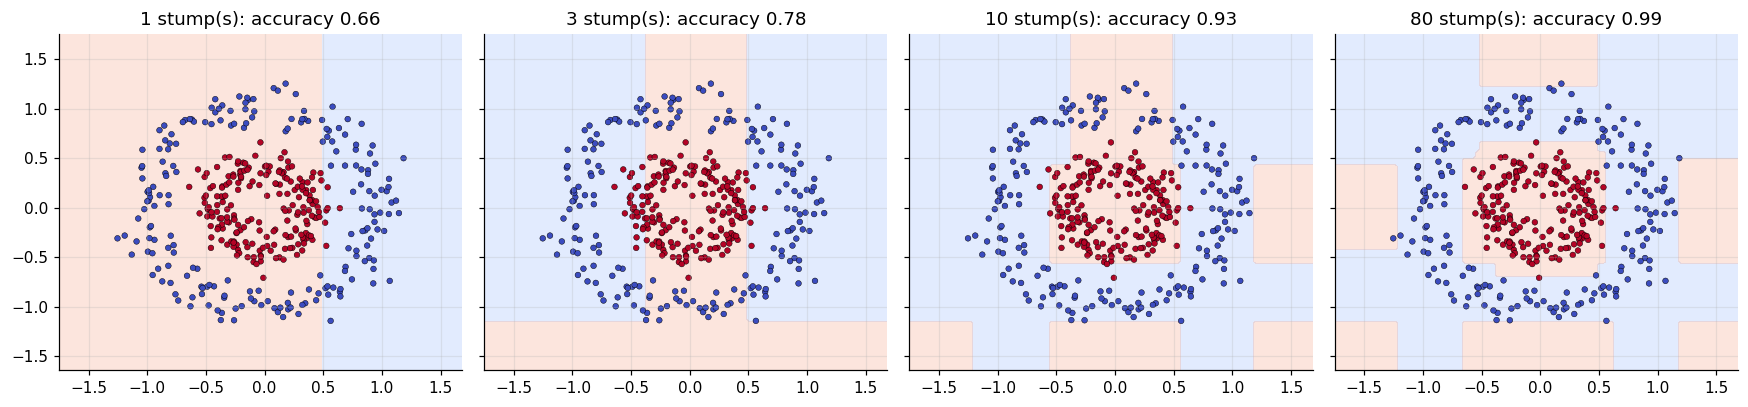

In [3]:
from sklearn.datasets import make_moons, make_circles
def plot_boundary(ax, model, X, y, cmap="coolwarm", n=150, pad=0.5):
    """Colour the plane by the model's predicted class, then draw the data on top."""
    gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, n), np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, n))
    pred = np.asarray(model.predict(np.c_[gx.ravel(), gy.ravel()])).reshape(gx.shape)
    K = len(np.unique(y))
    ax.contourf(gx, gy, pred, alpha=0.25, cmap=cmap, levels=np.arange(-0.5, K + 0.5) if K > 2 else [-0.5, 0.5, 1.5])
    ax.scatter(*X.T, c=y, cmap=cmap, s=14, edgecolor="k", linewidth=0.3)

X, y = make_circles(n_samples=400, factor=0.4, noise=0.12, random_state=0)
ypm = 2 * y - 1
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, n in zip(axes, [1, 3, 10, 80]):
    m = AdaBoostClassifier(n_estimators=n).fit(X, y); plot_boundary(ax, m, X, y, n=100); ax.set_title(f"{n} stump(s): accuracy {(m.predict(X) == y).mean():.2f}")
plt.tight_layout(); plt.show()

### 2. How the sample weights move

After each round the points the stump got **wrong** are up-weighted (`wᵢ ← wᵢ·e^{−α yᵢ h(xᵢ)}` then renormalise), so the next stump is forced to focus on them. Point size below is its weight. The stump's vote `α = ½ ln((1 − ε)/ε)` is large when its weighted error `ε` is small.

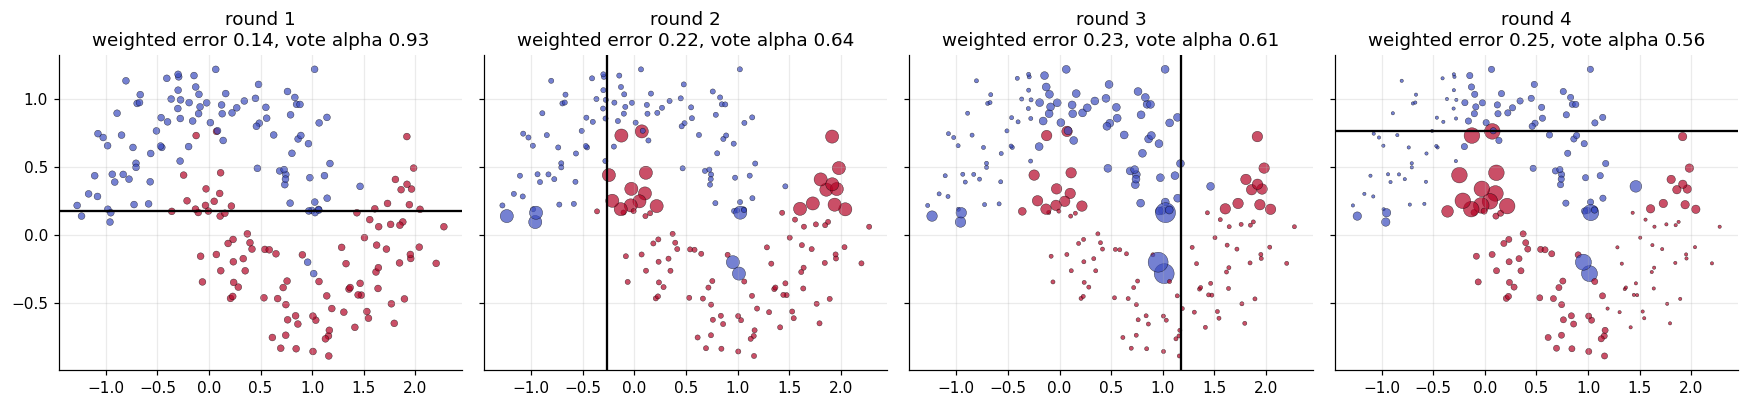

In [4]:
Xt, yt = make_moons(n_samples=200, noise=0.2, random_state=3); ypm = 2 * yt - 1
w = np.full(len(Xt), 1 / len(Xt))
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for r, ax in enumerate(axes):
    stump = _Stump().fit(Xt, ypm, w); pred = stump.predict(Xt)
    err = w[pred != ypm].sum(); alpha = 0.5 * np.log((1 - err) / err)
    ax.scatter(*Xt.T, c=yt, cmap="coolwarm", s=w * 4000, edgecolor="k", linewidth=0.3, alpha=0.7)
    (ax.axvline if stump.feature == 0 else ax.axhline)(stump.threshold, color="k")
    ax.set_title(f"round {r + 1}\nweighted error {err:.2f}, vote alpha {alpha:.2f}")
    w = w * np.exp(-alpha * ypm * pred); w /= w.sum()
plt.tight_layout(); plt.show()

### 3. Train and test error vs rounds

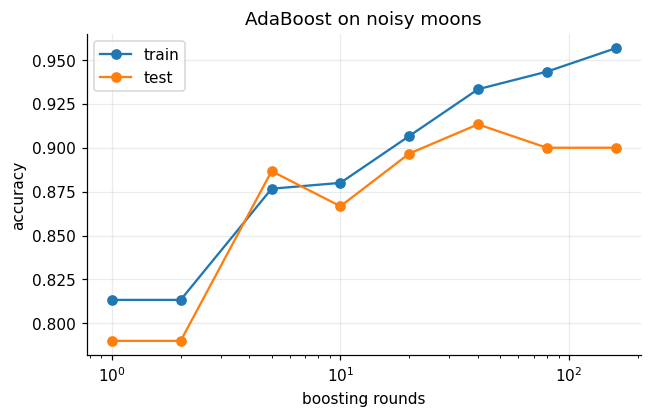

In [5]:
from sklearn.model_selection import train_test_split
Xa, ya = make_moons(n_samples=600, noise=0.3, random_state=1)
Xtr, Xte, ytr, yte = train_test_split(Xa, ya, test_size=0.5, random_state=0)
ns = [1, 2, 5, 10, 20, 40, 80, 160]
tr = [(AdaBoostClassifier(n_estimators=n).fit(Xtr, ytr).predict(Xtr) == ytr).mean() for n in ns]
te = [(AdaBoostClassifier(n_estimators=n).fit(Xtr, ytr).predict(Xte) == yte).mean() for n in ns]
plt.figure(figsize=(6.5, 3.8)); plt.semilogx(ns, tr, "o-", label="train"); plt.semilogx(ns, te, "o-", label="test")
plt.xlabel("boosting rounds"); plt.ylabel("accuracy"); plt.legend(); plt.title("AdaBoost on noisy moons"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import AdaBoostClassifier as SklearnAdaBoost
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.3, random_state=42
)

ours = AdaBoostClassifier(n_estimators=50).fit(X_train, y_train)
theirs = SklearnAdaBoost(
    estimator=DecisionTreeClassifier(max_depth=1), n_estimators=50, algorithm="SAMME", random_state=0
).fit(X_train, y_train)

acc_ours = (ours.predict(X_test) == y_test).mean()
acc_theirs = (theirs.predict(X_test) == y_test).mean()
print("breast cancer test accuracy: ours=%.4f sklearn=%.4f" % (acc_ours, acc_theirs))
assert abs(acc_ours - acc_theirs) < 0.03

breast cancer test accuracy: ours=0.9766 sklearn=0.9708


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def test_stump_finds_the_split():
    X = np.array([[1.0], [2.0], [3.0], [8.0], [9.0], [10.0]])
    y = np.array([-1, -1, -1, 1, 1, 1])
    stump = _Stump().fit(X, y, np.full(6, 1 / 6))
    assert (stump.predict(X) == y).all()
    assert 3 < stump.threshold < 8


def test_boosting_beats_a_single_stump():
    # positive class is the middle band: no single threshold can capture it
    rng = np.random.default_rng(0)
    X = rng.uniform(0, 10, size=(300, 1))
    y = np.where((X[:, 0] > 3) & (X[:, 0] < 7), "in", "out")

    one = AdaBoostClassifier(n_estimators=1).fit(X, y)
    many = AdaBoostClassifier(n_estimators=30).fit(X, y)
    acc = lambda m: (m.predict(X) == y).mean()
    assert acc(one) < 0.85
    assert acc(many) > 0.95


def test_rejects_multiclass():
    try:
        AdaBoostClassifier().fit(np.zeros((3, 2)), np.array([0, 1, 2]))
    except ValueError:
        return
    raise AssertionError("expected ValueError")

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_stump_finds_the_split
PASS test_boosting_beats_a_single_stump
PASS test_rejects_multiclass

all 3 tests passed


## Takeaways

- **Use it** to boost very weak learners (stumps) into a strong classifier; the historical first practical boosting algorithm.
- **Mechanics:** reweight samples (mistakes up), fit a stump on the weighted data, give it a vote `α = ½ ln((1 − ε)/ε)`. It minimises the **exponential loss**, which makes it sensitive to **label noise and outliers** (their weights grow without bound).
- **Compared with bagging:** boosting is sequential and reduces **bias**; bagging is parallel and reduces **variance**.
- **Interview line:** *"Sequentially fit weak learners on reweighted data, up-weighting what the last one got wrong; final prediction is an α-weighted vote."*